        MSSubClass  LotFrontage        LotArea  OverallQual  OverallCond  \
count  1460.000000  1460.000000    1460.000000  1460.000000  1460.000000   
mean     56.897260    69.863699   10516.828082     6.099315     5.575342   
std      42.300571    22.027677    9981.264932     1.382997     1.112799   
min      20.000000    21.000000    1300.000000     1.000000     1.000000   
25%      20.000000    60.000000    7553.500000     5.000000     5.000000   
50%      50.000000    69.000000    9478.500000     6.000000     5.000000   
75%      70.000000    79.000000   11601.500000     7.000000     6.000000   
max     190.000000   313.000000  215245.000000    10.000000     9.000000   

         YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1   BsmtFinSF2  ...  \
count  1460.000000   1460.000000  1460.000000  1460.000000  1460.000000  ...   
mean   1971.267808   1984.865753   103.117123   443.639726    46.549315  ...   
std      30.202904     20.645407   180.731373   456.098091   161.319273  ..

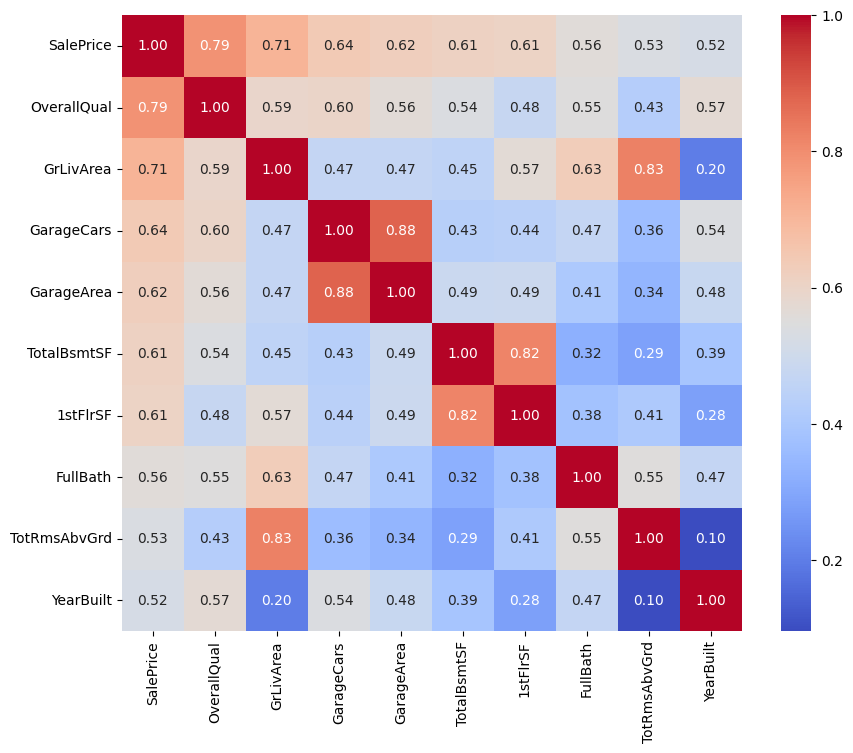

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train.csv')


num_df = df.select_dtypes(include=[np.number]).drop('Id', axis=1)
num_df = num_df.fillna(num_df.median())

print(num_df.describe())


top_corr = num_df.corr()['SalePrice'].abs().sort_values(ascending=False).head(10).index
plt.figure(figsize=(10, 8))
sns.heatmap(num_df[top_corr].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

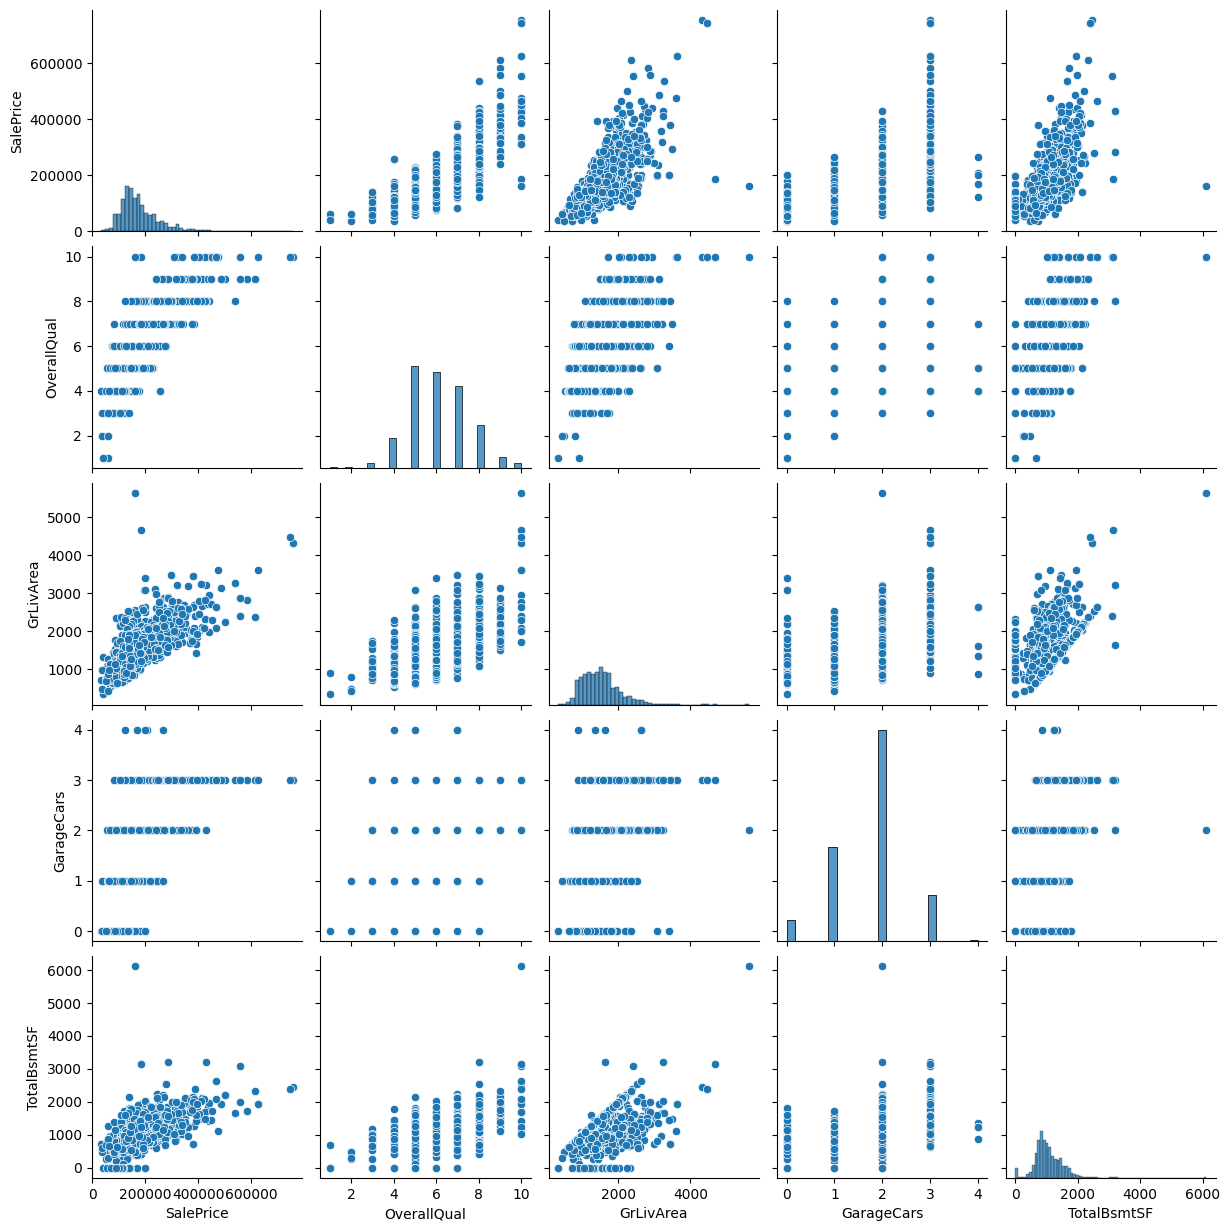

Базовый R2: 0.8230899421141546


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

sns.pairplot(num_df[['SalePrice', 'OverallQual', 'GrLivArea', 'GarageCars', 'TotalBsmtSF']])
plt.show()

X = num_df.drop('SalePrice', axis=1)
y = num_df['SalePrice']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression()
lr.fit(X_train, y_train)
print("Базовый R2:", lr.score(X_test, y_test))

In [3]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.ensemble import RandomForestRegressor


for name, scaler in [('Standard', StandardScaler()), ('MinMax', MinMaxScaler()), ('Robust', RobustScaler())]:
    X_tr_s = scaler.fit_transform(X_train)
    X_te_s = scaler.transform(X_test)
    model = LinearRegression().fit(X_tr_s, y_train)
    print(f"R2 ({name}): {model.score(X_te_s, y_test):.4f}")

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

importances = pd.Series(rf.feature_importances_, index=X.columns)
print("\nТоп-10 важных признаков:\n", importances.sort_values(ascending=False).head(10))


selected_cols = importances[importances > 0.01].index
print(f"\nОтобрано признаков: {len(selected_cols)} из {X.shape[1]}")

lr_sel = LinearRegression().fit(X_train[selected_cols], y_train)
print(f"R2 после отбора признаков: {lr_sel.score(X_test[selected_cols], y_test):.4f}")


R2 (Standard): 0.8231
R2 (MinMax): 0.8231
R2 (Robust): 0.8231

Топ-10 важных признаков:
 OverallQual    0.563337
GrLivArea      0.124482
TotalBsmtSF    0.037775
2ndFlrSF       0.035807
BsmtFinSF1     0.033843
1stFlrSF       0.030112
LotArea        0.021188
GarageArea     0.018893
YearBuilt      0.017692
GarageCars     0.013726
dtype: float64

Отобрано признаков: 12 из 36
R2 после отбора признаков: 0.8045


In [4]:
df_new = num_df.copy()


df_new['TotalSF'] = df_new['TotalBsmtSF'] + df_new['1stFlrSF'] + df_new['2ndFlrSF']
df_new['HouseAge'] = df_new['YrSold'] - df_new['YearBuilt']
df_new['TotalBath'] = df_new['FullBath'] + 0.5 * df_new['HalfBath'] + df_new['BsmtFullBath']

X_new = df_new.drop('SalePrice', axis=1)
y_new = df_new['SalePrice']

X_tr_n, X_te_n, y_tr_n, y_te_n = train_test_split(X_new, y_new, test_size=0.2, random_state=42)

lr_new = LinearRegression().fit(X_tr_n, y_tr_n)
print(f"R2 с новыми признаками: {lr_new.score(X_te_n, y_te_n):.4f}")


R2 с новыми признаками: 0.8231
